Model ladder and model selection

Days 6-7. Walk-forward test of 10 models (single feature -> linear -> splines -> interactions -> trees).
Each year 2021-2024 is predicted by a model trained only on earlier years (48 out-of-sample months).
Only train + validation rows are used (2020-2024), test rows are dropped right after loading.
Target for fitting: `fwd_1m_rank - 0.5`. Evaluation label: `fwd_1m`.
Outputs: `reports/model_comparison.csv`, `reports/frozen_model.json` and 4 charts in `reports/figures/`.

## Setup

In [1]:
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.evaluate import rank_ic_by_date, evaluate_score, bucket_returns, top_k_returns, bootstrap_mean_ci
from src.models import (walk_forward_predict, tune_params, prepare_model_data, add_standard_interactions,
                        build_model_registry, make_elastic_net, make_lightgbm, COMPOSITE_PRIORS)

MODEL_TABLE_PATH = "../data/processed/model_table.csv"
BENCHMARK_EW_PATH = "../data/processed/benchmark_ew.csv"
BENCHMARK_NIFTY_PATH = "../data/processed/benchmark_nifty.csv"
COMPARISON_PATH = "../reports/model_comparison.csv"
FROZEN_PATH = "../reports/frozen_model.json"
WALK_FORWARD_STEPS_PATH = "../reports/walk_forward_steps.csv"
FIGURE_FOLDER = "../reports/figures/"

# nothing after this date may appear anywhere below
LAST_ALLOWED_DATE = pd.Timestamp("2024-12-31")

## Load data (train + validation only)

In [2]:
model_table = pd.read_csv(MODEL_TABLE_PATH, parse_dates=["Date"])

# state z-scores are nan early on (they need 12 months of history), prepare_model_data fills them with 0
keep_rows = model_table["split"].isin(["train", "validation"]) & model_table["has_label_1m"]
z_columns = [name for name in model_table.columns if name.endswith("_z")]
print("nans in state z columns before filling:")
print(model_table.loc[keep_rows, z_columns].isna().sum())

# drops test and warm-up rows right away and rows with no 1-month label, adds the target y (centered rank)
df, feature_cols, state_z_cols = prepare_model_data(model_table, ["train", "validation"], True)

print()
print("rows:", len(df), "| months:", df["Date"].nunique(), "| splits:", sorted(df["split"].unique()))
print("first date:", df["Date"].min().date(), "| last date:", df["Date"].max().date())
print("number of features:", len(feature_cols))
print("state z columns:", state_z_cols)

nans in state z columns before filling:
mkt_ret_1m_z         0
mkt_ret_12m_z      330
mkt_vol_63d_z       60
xs_dispersion_z      0
dtype: int64

rows: 1800 | months: 60 | splits: ['train', 'validation']
first date: 2020-01-31 | last date: 2024-12-31
number of features: 17
state z columns: ['mkt_ret_1m_z', 'mkt_ret_12m_z', 'mkt_vol_63d_z', 'xs_dispersion_z']


## Interaction columns

In [3]:
# the three momentum features are multiplied by 3 stock features (feature x feature)
# and by 3 market-state variables (feature x state), see add_standard_interactions in src/models.py
df, feature_x_feature_cols, feature_x_state_cols = add_standard_interactions(df)

print("feature x feature columns:", len(feature_x_feature_cols))
print(feature_x_feature_cols)
print("feature x state columns:", len(feature_x_state_cols))
print(feature_x_state_cols)

feature x feature columns: 9
['mom_1m_n_x_retvol_63d_n', 'mom_1m_n_x_amihud_21d_n', 'mom_1m_n_x_abn_turnover_n', 'mom_6_1_n_x_retvol_63d_n', 'mom_6_1_n_x_amihud_21d_n', 'mom_6_1_n_x_abn_turnover_n', 'mom_12_1_n_x_retvol_63d_n', 'mom_12_1_n_x_amihud_21d_n', 'mom_12_1_n_x_abn_turnover_n']
feature x state columns: 9
['mom_1m_n_x_mkt_vol_63d_z', 'mom_1m_n_x_mkt_ret_12m_z', 'mom_1m_n_x_xs_dispersion_z', 'mom_6_1_n_x_mkt_vol_63d_z', 'mom_6_1_n_x_mkt_ret_12m_z', 'mom_6_1_n_x_xs_dispersion_z', 'mom_12_1_n_x_mkt_vol_63d_z', 'mom_12_1_n_x_mkt_ret_12m_z', 'mom_12_1_n_x_xs_dispersion_z']


## Part B: model registry

In [4]:
# all ten models (function, features, hyperparameter grid, default) are defined in src/models.py
# order = simplicity order (M0 simplest, M9 most complex)
model_registry = build_model_registry(feature_cols, feature_x_feature_cols, feature_x_state_cols)
tree_cols = model_registry["M9"]["features"]

for name in model_registry:
    spec = model_registry[name]
    n_settings = 1 if spec["grid"] is None else len(spec["grid"])
    print(name, "|", spec["label"], "| features:", len(spec["features"]), "| grid settings:", n_settings)

M0 | best single feature (mom_1m_n, sign from train ic) | features: 1 | grid settings: 1
M1 | equal-weight composite of 7 features with a prior | features: 7 | grid settings: 1
M2 | ols on 17 features | features: 17 | grid settings: 1
M3 | elastic net on 17 features | features: 17 | grid settings: 9
M4 | splines + ridge (nonlinear, no interactions) | features: 17 | grid settings: 3
M5 | elastic net + feature x feature | features: 26 | grid settings: 9
M6 | elastic net + feature x state | features: 26 | grid settings: 9
M7 | elastic net + both interaction sets | features: 35 | grid settings: 9
M8 | random forest | features: 20 | grid settings: 4
M9 | lightgbm | features: 20 | grid settings: 4


## Part A: walk-forward predictions for every model

In [5]:
wf_predictions = {}
wf_step_logs = {}

for name in model_registry:
    spec = model_registry[name]
    start_time = time.time()

    predictions, step_log = walk_forward_predict(df, spec["function"], spec["features"],
                                                 param_grid=spec["grid"], default_params=spec["default"],
                                                 start_year=2021, end_year=2024)
    wf_predictions[name] = predictions
    wf_step_logs[name] = step_log

    print(name, "done in", round(time.time() - start_time, 1), "s | rows:", len(predictions))
    for i in range(len(step_log)):
        print("    ", step_log.loc[i, "year"], "train rows:", step_log.loc[i, "n_train"], "| params:", step_log.loc[i, "params"])

M0 done in 0.1 s | rows: 1440
     2021 train rows: 360 | params: {}
     2022 train rows: 720 | params: {}
     2023 train rows: 1080 | params: {}
     2024 train rows: 1440 | params: {}
M1 done in 0.0 s | rows: 1440
     2021 train rows: 360 | params: {}
     2022 train rows: 720 | params: {}
     2023 train rows: 1080 | params: {}
     2024 train rows: 1440 | params: {}
M2 done in 0.0 s | rows: 1440
     2021 train rows: 360 | params: {}
     2022 train rows: 720 | params: {}
     2023 train rows: 1080 | params: {}
     2024 train rows: 1440 | params: {}


C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


M3 done in 0.3 s | rows: 1440
     2021 train rows: 360 | params: {'alpha': 0.01, 'l1_ratio': 0.5}
     2022 train rows: 720 | params: {'alpha': 0.1, 'l1_ratio': 0.2}
     2023 train rows: 1080 | params: {'alpha': 0.1, 'l1_ratio': 0.2}
     2024 train rows: 1440 | params: {'alpha': 0.01, 'l1_ratio': 0.8}
M4 done in 0.2 s | rows: 1440
     2021 train rows: 360 | params: {'alpha': 100}
     2022 train rows: 720 | params: {'alpha': 100}
     2023 train rows: 1080 | params: {'alpha': 100}
     2024 train rows: 1440 | params: {'alpha': 1}


C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\

...

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


M7 done in 0.3 s | rows: 1440
     2021 train rows: 360 | params: {'alpha': 0.01, 'l1_ratio': 0.5}
     2022 train rows: 720 | params: {'alpha': 0.1, 'l1_ratio': 0.2}
     2023 train rows: 1080 | params: {'alpha': 0.1, 'l1_ratio': 0.2}
     2024 train rows: 1440 | params: {'alpha': 0.001, 'l1_ratio': 0.2}


M8 done in 6.3 s | rows: 1440
     2021 train rows: 360 | params: {'max_depth': 3, 'min_samples_leaf': 50, 'n_estimators': 300, 'random_state': 42}
     2022 train rows: 720 | params: {'max_depth': 3, 'min_samples_leaf': 20, 'n_estimators': 300, 'random_state': 42}
     2023 train rows: 1080 | params: {'max_depth': 3, 'min_samples_leaf': 50, 'n_estimators': 300, 'random_state': 42}
     2024 train rows: 1440 | params: {'max_depth': 5, 'min_samples_leaf': 20, 'n_estimators': 300, 'random_state': 42}


M9 done in 2.4 s | rows: 1440
     2021 train rows: 360 | params: {'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 60, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
     2022 train rows: 720 | params: {'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 60, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
     2023 train rows: 1080 | params: {'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 60, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
     2024 train rows: 1440 | params: {'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}


In [6]:
# save the walk-forward step logs: dates and chosen hyperparameters per model per year
step_tables = []
for name in model_registry:
    step_table = wf_step_logs[name].copy()
    step_table.insert(0, "model", name)

    # the params are a dictionary, store them as text so they fit in one csv cell
    params_as_text = []
    for params in step_table["params"]:
        params_as_text.append(json.dumps(params))
    step_table["params"] = params_as_text
    step_tables.append(step_table)

walk_forward_steps = pd.concat(step_tables).reset_index(drop=True)
walk_forward_steps.to_csv(WALK_FORWARD_STEPS_PATH, index=False)

print("saved", WALK_FORWARD_STEPS_PATH, "| rows:", len(walk_forward_steps), "(10 models x 4 years)")
print(walk_forward_steps[walk_forward_steps["model"] == "M3"].to_string(index=False))

saved ../reports/walk_forward_steps.csv | rows: 40 (10 models x 4 years)
model  year  n_train  n_predict max_train_date min_predict_date                           params
   M3  2021      360        360     2020-12-31       2021-01-29 {"alpha": 0.01, "l1_ratio": 0.5}
   M3  2022      720        360     2021-12-31       2022-01-31  {"alpha": 0.1, "l1_ratio": 0.2}
   M3  2023     1080        360     2022-12-30       2023-01-31  {"alpha": 0.1, "l1_ratio": 0.2}
   M3  2024     1440        360     2023-12-29       2024-01-31 {"alpha": 0.01, "l1_ratio": 0.8}


## Part C: evaluation

In [7]:
# attach the true fwd_1m to every model's predictions
label_table = df[["Date", "Ticker", "fwd_1m"]]
scored = {}
ic_by_model = {}

for name in model_registry:
    scored[name] = pd.merge(wf_predictions[name], label_table, on=["Date", "Ticker"], how="left", validate="one_to_one")
    ic_by_model[name] = rank_ic_by_date(scored[name], "score")

# a model that gives all 30 stocks the same score in a month has no defined ic that month
print("months with an undefined ic (constant score), per model:")
for name in model_registry:
    print(name, ic_by_model[name].isna().sum(), "of", len(ic_by_model[name]))

months with an undefined ic (constant score), per model:
M0 0 of 48
M1 0 of 48
M2 0 of 48
M3 0 of 48
M4 0 of 48
M5 0 of 48
M6 0 of 48
M7 0 of 48
M8 0 of 48
M9 0 of 48


In [8]:
benchmark_ew_table = pd.read_csv(BENCHMARK_EW_PATH, parse_dates=["Date"])
benchmark_ew = benchmark_ew_table.set_index("Date")["fwd_1m"]

summary_keys = ["mean_ic", "icir", "t_stat", "pct_positive", "monotonicity",
                "top5_excess_ew", "top10_excess_ew", "top5_hit_rate_ew", "top10_hit_rate_ew", "top5_turnover"]

rows = []
for name in model_registry:
    all_months = scored[name]
    val_months = all_months[all_months["Date"].dt.year == 2024]

    wf_stats = evaluate_score(all_months, "score", k_list=[5, 10], benchmark_ew=benchmark_ew)
    val_stats = evaluate_score(val_months, "score", k_list=[5, 10], benchmark_ew=benchmark_ew)
    ci_low, ci_high = bootstrap_mean_ci(ic_by_model[name], n_boot=2000, seed=42, ci_level=90)

    row = {"model": name, "label": model_registry[name]["label"], "n_features": len(model_registry[name]["features"])}
    for key in summary_keys:
        row["wf_" + key] = wf_stats[key]
    row["wf_ic_ci_low"] = ci_low
    row["wf_ic_ci_high"] = ci_high
    row["wf_n_months"] = wf_stats["n_months"]
    for key in summary_keys:
        row["val_" + key] = val_stats[key]
    row["val_n_months"] = val_stats["n_months"]
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison.to_csv(COMPARISON_PATH, index=False)
comparison = comparison.set_index("model")

print("saved", COMPARISON_PATH)
print()
print("walk-forward (all 48 months):")
print(comparison[["wf_mean_ic", "wf_ic_ci_low", "wf_ic_ci_high", "wf_icir", "wf_t_stat", "wf_pct_positive",
                  "wf_monotonicity", "wf_top5_excess_ew", "wf_top10_excess_ew", "wf_top5_hit_rate_ew",
                  "wf_top5_turnover"]].round(4).to_string())
print()
print("validation 2024 only (12 months):")
print(comparison[["val_mean_ic", "val_icir", "val_t_stat", "val_pct_positive", "val_monotonicity",
                  "val_top5_excess_ew", "val_top10_excess_ew", "val_top5_hit_rate_ew",
                  "val_top5_turnover"]].round(4).to_string())

saved ../reports/model_comparison.csv

walk-forward (all 48 months):
       wf_mean_ic  wf_ic_ci_low  wf_ic_ci_high  wf_icir  wf_t_stat  wf_pct_positive  wf_monotonicity  wf_top5_excess_ew  wf_top10_excess_ew  wf_top5_hit_rate_ew  wf_top5_turnover
model                                                                                                                                                                             
M0         0.0374       -0.0162         0.0956   0.1519     1.0527          56.2500              0.5             0.0043              0.0020              62.5000            0.8553
M1         0.0169       -0.0483         0.0812   0.0620     0.4295          54.1667              0.1             0.0028             -0.0003              60.4167            0.6170
M2        -0.0341       -0.0790         0.0088  -0.1773    -1.2286          43.7500             -0.8            -0.0031             -0.0040              37.5000            0.6936
M3         0.0038       -0.0480     

## Part D: model selection (rule fixed in advance)

In [9]:
model_order = list(model_registry.keys())
selection_lines = []

# rule 1: only models with a positive mean ic on the 2024 validation months
eligible = []
for name in model_order:
    if comparison.loc[name, "val_mean_ic"] > 0:
        eligible.append(name)
selection_lines.append("rule 1: eligible models (2024 validation mean ic > 0): " + str(eligible))

if len(eligible) == 0:
    # rule 4
    chosen_model = "M1"
    selection_lines.append("rule 4: no model beats zero on validation -> pick M1")
    print("no model beats zero on validation")
else:
    # rule 2: highest walk-forward mean ic among the eligible ones
    best_name = eligible[0]
    for name in eligible:
        if comparison.loc[name, "wf_mean_ic"] > comparison.loc[best_name, "wf_mean_ic"]:
            best_name = name
    best_ic = comparison.loc[best_name, "wf_mean_ic"]
    selection_lines.append("rule 2: highest 48-month walk-forward mean ic: " + best_name + " (" + str(round(best_ic, 4)) + ")")

    # rule 3: the simplest eligible model within 0.01 of that best ic wins (eligible is already in simplicity order)
    chosen_model = best_name
    for name in eligible:
        if comparison.loc[name, "wf_mean_ic"] >= best_ic - 0.01:
            chosen_model = name
            break
    selection_lines.append("rule 3: simplest eligible model with mean ic >= " + str(round(best_ic - 0.01, 4)) + ": " + chosen_model
                           + " (" + str(round(comparison.loc[chosen_model, "wf_mean_ic"], 4)) + ")")

selection_lines.append("chosen model: " + chosen_model + " = " + model_registry[chosen_model]["label"])
for line in selection_lines:
    print(line)

no model beats zero on validation
rule 1: eligible models (2024 validation mean ic > 0): []
rule 4: no model beats zero on validation -> pick M1
chosen model: M1 = equal-weight composite of 7 features with a prior


In [10]:
# save the chosen model so it can be refit and run once on the test period
chosen_spec = model_registry[chosen_model]
frozen = {
    "chosen_model": chosen_model,
    "label": chosen_spec["label"],
    "target": "fwd_1m_rank - 0.5",
    "feature_cols": chosen_spec["features"],
    "hyperparameter_grid": chosen_spec["grid_options"],
    "default_params_first_year": chosen_spec["default"],
    "walk_forward_mean_ic_48m": float(comparison.loc[chosen_model, "wf_mean_ic"]),
    "validation_2024_mean_ic": float(comparison.loc[chosen_model, "val_mean_ic"]),
    "selection_reasoning": selection_lines,
}
if chosen_model == "M0":
    frozen["note"] = "sign of mom_1m_n is re-estimated from the training ic every time the model is fit"
if chosen_model == "M1":
    frozen["composite_priors"] = COMPOSITE_PRIORS

with open(FROZEN_PATH, "w") as frozen_file:
    json.dump(frozen, frozen_file, indent=2)

print("saved", FROZEN_PATH)
print("features in the frozen model:", len(frozen["feature_cols"]))

saved ../reports/frozen_model.json
features in the frozen model: 7


## Part E: decomposition (what does each extra piece of complexity add?)

In [11]:
decomposition_steps = [
    ("M3", "linear (elastic net)"),
    ("M4", "+ nonlinearity within features"),
    ("M5", "+ feature x feature interactions"),
    ("M6", "+ feature x state interactions"),
    ("M7", "+ both interaction sets"),
    ("M9", "trees, everything (lightgbm)"),
]

linear_ic = comparison.loc["M3", "wf_mean_ic"]
decomposition_rows = []
for name, step_label in decomposition_steps:
    decomposition_rows.append({
        "model": name,
        "what is added": step_label,
        "wf_mean_ic": comparison.loc[name, "wf_mean_ic"],
        "change_vs_M3": comparison.loc[name, "wf_mean_ic"] - linear_ic,
        "ci_low": comparison.loc[name, "wf_ic_ci_low"],
        "ci_high": comparison.loc[name, "wf_ic_ci_high"],
        "val_2024_mean_ic": comparison.loc[name, "val_mean_ic"],
    })

decomposition = pd.DataFrame(decomposition_rows)
print("walk-forward mean rank ic (48 months), change vs the linear model M3:")
print(decomposition.round(4).to_string(index=False))

walk-forward mean rank ic (48 months), change vs the linear model M3:
model                    what is added  wf_mean_ic  change_vs_M3  ci_low  ci_high  val_2024_mean_ic
   M3             linear (elastic net)      0.0038        0.0000 -0.0480   0.0570           -0.1046
   M4   + nonlinearity within features     -0.0121       -0.0159 -0.0569   0.0361           -0.0849
   M5 + feature x feature interactions      0.0036       -0.0002 -0.0473   0.0557           -0.1020
   M6   + feature x state interactions      0.0101        0.0063 -0.0419   0.0640           -0.1253
   M7          + both interaction sets      0.0181        0.0142 -0.0307   0.0712           -0.0836
   M9     trees, everything (lightgbm)     -0.0228       -0.0266 -0.0585   0.0166           -0.0602


## Part F: what did the models learn? (refit on all 2020-2024 rows)

In [12]:
# hyperparameters are tuned the same way as inside the walk-forward: inner validation year = 2024, inner train = 2020-2023
def refit_elastic_net(model_name):
    spec = model_registry[model_name]
    params = tune_params(spec["function"], df, spec["features"], spec["grid"], spec["default"], 2025)
    model = make_elastic_net(params)
    model.fit(df[spec["features"]], df["y"])
    return model, params

def print_coefficients(model_name, max_rows=20):
    model, params = refit_elastic_net(model_name)
    feature_names = model_registry[model_name]["features"]
    coefficients = pd.Series(model.named_steps["enet"].coef_, index=feature_names)
    order = coefficients.abs().sort_values(ascending=False).index
    n_zero = (coefficients == 0).sum()
    print(model_name, "| tuned params:", params, "| coefficients set to exactly 0:", n_zero, "of", len(coefficients))
    print("(coefficients are on standardized columns, so their sizes can be compared)")
    print(coefficients[order].head(max_rows).round(5).to_string())
    print()

print_coefficients("M3")

M3 | tuned params: {'alpha': 0.001, 'l1_ratio': 0.2} | coefficients set to exactly 0: 3 of 17
(coefficients are on standardized columns, so their sizes can be compared)
retvol_21d_n          -0.01970
mom_1m_n              -0.01937
idiovol_252d_n         0.01597
chmom_n               -0.01583
amihud_21d_secrel      0.01156
maxret_21d_n           0.01058
mom_12_1_n            -0.00956
abn_turnover_secrel    0.00889
retvol_63d_secrel     -0.00827
turnover_cv_21d_n      0.00491
amihud_21d_n          -0.00392
retvol_63d_n           0.00284
mom_12_1_secrel        0.00119
beta_252d_n            0.00025
mom_6_1_n              0.00000
abn_turnover_n         0.00000
log_turnover_21d_n     0.00000



C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [13]:
print_coefficients("M7", max_rows=20)

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


M7 | tuned params: {'alpha': 0.001, 'l1_ratio': 0.2} | coefficients set to exactly 0: 1 of 35
(coefficients are on standardized columns, so their sizes can be compared)
mom_12_1_n_x_mkt_vol_63d_z     -0.04597
mom_6_1_n_x_mkt_vol_63d_z       0.03405
mom_6_1_n_x_xs_dispersion_z    -0.02864
mom_12_1_n_x_retvol_63d_n      -0.02495
mom_12_1_n_x_xs_dispersion_z    0.02446
mom_6_1_n_x_retvol_63d_n        0.01939
mom_1m_n                       -0.01858
chmom_n                        -0.01731
mom_12_1_n                     -0.01527
retvol_21d_n                   -0.01513
mom_6_1_n_x_mkt_ret_12m_z       0.01439
idiovol_252d_n                  0.01250
mom_12_1_n_x_mkt_ret_12m_z     -0.01184
mom_1m_n_x_mkt_ret_12m_z       -0.01141
maxret_21d_n                    0.01062
amihud_21d_secrel               0.01062
mom_1m_n_x_xs_dispersion_z      0.00825
mom_1m_n_x_mkt_vol_63d_z       -0.00758
abn_turnover_secrel             0.00746
mom_1m_n_x_amihud_21d_n         0.00691



C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [14]:
# lightgbm: how much each feature reduced the error (gain), as a share of the total
spec_m9 = model_registry["M9"]
params_m9 = tune_params(spec_m9["function"], df, spec_m9["features"], spec_m9["grid"], spec_m9["default"], 2025)
lgbm_model = make_lightgbm(params_m9)
lgbm_model.fit(df[spec_m9["features"]], df["y"])

importance = pd.Series(lgbm_model.feature_importances_, index=spec_m9["features"])
importance_share = importance / importance.sum() * 100
print("M9 tuned params:", params_m9)
print("feature importance (gain, % of total):")
print(importance_share.sort_values(ascending=False).round(2).to_string())

M9 tuned params: {'num_leaves': 15, 'learning_rate': 0.03, 'n_estimators': 200, 'min_child_samples': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
feature importance (gain, % of total):
xs_dispersion_z        8.30
mom_12_1_n             6.74
mkt_vol_63d_z          6.61
mom_1m_n               6.60
maxret_21d_n           6.38
turnover_cv_21d_n      6.36
beta_252d_n            5.64
abn_turnover_n         5.48
mkt_ret_12m_z          5.47
mom_6_1_n              5.26
retvol_21d_n           5.05
log_turnover_21d_n     4.88
chmom_n                4.73
retvol_63d_n           4.62
idiovol_252d_n         4.04
amihud_21d_n           3.47
mom_12_1_secrel        2.76
abn_turnover_secrel    2.69
retvol_63d_secrel      2.62
amihud_21d_secrel      2.29


## Checks

In [15]:
check_results = {}

def report_check(name, passed):
    check_results[name] = passed
    if passed:
        print("PASS:", name)
    else:
        print("FAIL:", name)

In [16]:
# check 1: no test-period date anywhere
latest_dates = [df["Date"].max(), model_table[keep_rows]["Date"].max()]
for name in model_registry:
    latest_dates.append(wf_predictions[name]["Date"].max())
    latest_dates.append(wf_step_logs[name]["min_predict_date"].max())

print("latest date found in any table:", max(latest_dates).date())
print("splits in the data:", sorted(df["split"].unique()))
report_check("1. no test-period date appears anywhere (latest date <= 2024-12-31, splits = train + validation)",
             max(latest_dates) <= LAST_ALLOWED_DATE and sorted(df["split"].unique()) == ["train", "validation"])

latest date found in any table: 2024-12-31
splits in the data: ['train', 'validation']
PASS: 1. no test-period date appears anywhere (latest date <= 2024-12-31, splits = train + validation)


In [17]:
# check 2: in every walk-forward step the training data ends before the first prediction date
all_steps_ok = True
n_steps = 0
for name in model_registry:
    step_log = wf_step_logs[name]
    for i in range(len(step_log)):
        n_steps = n_steps + 1
        if not step_log.loc[i, "max_train_date"] < step_log.loc[i, "min_predict_date"]:
            all_steps_ok = False

print("steps checked:", n_steps, "(10 models x 4 years)")
print("example (M9):")
print(wf_step_logs["M9"][["year", "n_train", "n_predict", "max_train_date", "min_predict_date"]].to_string(index=False))
report_check("2. every walk-forward step has max train date < min predict date", all_steps_ok)

steps checked: 40 (10 models x 4 years)
example (M9):
 year  n_train  n_predict max_train_date min_predict_date
 2021      360        360     2020-12-31       2021-01-29
 2022      720        360     2021-12-31       2022-01-31
 2023     1080        360     2022-12-30       2023-01-31
 2024     1440        360     2023-12-29       2024-01-31
PASS: 2. every walk-forward step has max train date < min predict date


In [18]:
# check 3: every model returns one score for every (Date, Ticker) in 2021-2024
expected_rows = df[df["Date"] >= pd.Timestamp("2021-01-01")][["Date", "Ticker"]]
expected_keys = set(zip(expected_rows["Date"], expected_rows["Ticker"]))

all_complete = True
for name in model_registry:
    predictions = wf_predictions[name]
    keys = set(zip(predictions["Date"], predictions["Ticker"]))
    complete = (len(predictions) == 48 * 30) and (keys == expected_keys) and predictions["score"].notna().all()
    if not complete:
        all_complete = False
        print("problem with", name, "rows:", len(predictions))

print("expected rows per model:", len(expected_rows), "(48 months x 30 stocks)")
report_check("3. every model returns a score for every (Date, Ticker) in 2021-2024 (48 x 30 rows)", all_complete)

expected rows per model: 1440 (48 months x 30 stocks)
PASS: 3. every model returns a score for every (Date, Ticker) in 2021-2024 (48 x 30 rows)


In [19]:
# check 4: recompute M0 by hand with the evaluate functions and compare with the walk-forward result
m0_scores = []
for year in range(2021, 2025):
    year_start = pd.Timestamp(str(year) + "-01-01")
    train_part = df[df["Date"] < year_start]
    year_part = df[(df["Date"] >= year_start) & (df["Date"] < pd.Timestamp(str(year + 1) + "-01-01"))].copy()

    train_ic = rank_ic_by_date(train_part, "mom_1m_n", "fwd_1m").mean()
    print(year, "train-only mean ic of mom_1m_n:", round(train_ic, 4), "-> sign", int(np.sign(train_ic)))
    year_part["score"] = np.sign(train_ic) * year_part["mom_1m_n"]
    m0_scores.append(year_part)

m0_by_hand = pd.concat(m0_scores)
by_hand_ic = rank_ic_by_date(m0_by_hand, "score").mean()
pipeline_ic = comparison.loc["M0", "wf_mean_ic"]
print("M0 mean ic by hand:", round(by_hand_ic, 6), "| from the pipeline:", round(pipeline_ic, 6))
report_check("4. M0 walk-forward ic matches a direct recomputation with src/evaluate.py", abs(by_hand_ic - pipeline_ic) < 1e-12)

2021 train-only mean ic of mom_1m_n: -0.0967 -> sign -1
2022 train-only mean ic of mom_1m_n: -0.1397 -> sign -1
2023 train-only mean ic of mom_1m_n: -0.121 -> sign -1
2024 train-only mean ic of mom_1m_n: -0.0911 -> sign -1
M0 mean ic by hand: 0.037384 | from the pipeline: 0.037384
PASS: 4. M0 walk-forward ic matches a direct recomputation with src/evaluate.py


In [20]:
# check 5 (extra): scramble every label from 2023 on, then rerun 2021-2022
# predictions for 2021-2022 must not move, because they may only use labels from before 2021 / 2022
random_state = np.random.RandomState(0)
scrambled = df.copy()
late_rows = scrambled["Date"] >= pd.Timestamp("2023-01-01")
scrambled.loc[late_rows, "y"] = random_state.rand(late_rows.sum())
scrambled.loc[late_rows, "fwd_1m"] = random_state.rand(late_rows.sum())

all_unchanged = True
for name in model_registry:
    spec = model_registry[name]
    scrambled_predictions, scrambled_log = walk_forward_predict(scrambled, spec["function"], spec["features"],
                                                                param_grid=spec["grid"], default_params=spec["default"],
                                                                start_year=2021, end_year=2022)
    original = wf_predictions[name]
    original = original[original["Date"] < pd.Timestamp("2023-01-01")]
    same = np.allclose(original["score"].to_numpy(), scrambled_predictions["score"].to_numpy(), rtol=1e-7, atol=1e-9)
    if not same:
        all_unchanged = False
        print("predictions moved for", name)

report_check("5. scrambling labels from 2023 on does not change any 2021-2022 prediction", all_unchanged)

# and the opposite: scrambling labels from 2021 on (legit training data for 2022) must change a learned model
scrambled_2021 = df.copy()
rows_2021 = scrambled_2021["Date"] >= pd.Timestamp("2021-01-01")
scrambled_2021.loc[rows_2021, "y"] = random_state.rand(rows_2021.sum())
scrambled_2021.loc[rows_2021, "fwd_1m"] = random_state.rand(rows_2021.sum())
spec = model_registry["M3"]
test_predictions, test_log = walk_forward_predict(scrambled_2021, spec["function"], spec["features"],
                                                  param_grid=spec["grid"], default_params=spec["default"],
                                                  start_year=2022, end_year=2022)
original_2022 = wf_predictions["M3"][wf_predictions["M3"]["Date"].dt.year == 2022]
moved = not np.allclose(original_2022["score"].to_numpy(), test_predictions["score"].to_numpy())
report_check("5b. the scramble test can detect a change (M3 2022 predictions move when 2021 labels are scrambled)", moved)

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\

C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


PASS: 5. scrambling labels from 2023 on does not change any 2021-2022 prediction
PASS: 5b. the scramble test can detect a change (M3 2022 predictions move when 2021 labels are scrambled)


C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Archit\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Charts

In [21]:
# colors: blue, orange, aqua (first slots of the validated palette), grey for reference lines
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
GREY = "#8a8a86"

def style_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, color="#e3e2de", linewidth=0.6)
    ax.set_axisbelow(True)

print("chosen model:", chosen_model)

chosen model: M1


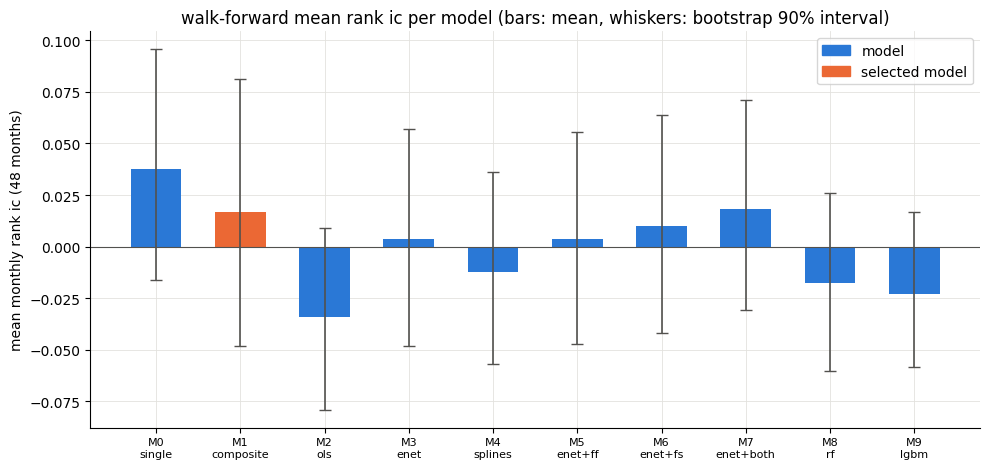

In [22]:
# chart 1: 48-month mean ic per model with the bootstrap 90% interval
names = list(model_registry.keys())
means = []
lower_errors = []
upper_errors = []
bar_colors = []
for name in names:
    mean_ic = comparison.loc[name, "wf_mean_ic"]
    means.append(mean_ic)
    lower_errors.append(mean_ic - comparison.loc[name, "wf_ic_ci_low"])
    upper_errors.append(comparison.loc[name, "wf_ic_ci_high"] - mean_ic)
    if name == chosen_model:
        bar_colors.append(ORANGE)
    else:
        bar_colors.append(BLUE)

tick_labels = [name + "\n" + model_registry[name]["short"] for name in names]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(range(len(names)), means, color=bar_colors, width=0.6, yerr=[lower_errors, upper_errors],
       error_kw={"ecolor": "#52514e", "elinewidth": 1.2, "capsize": 4})
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(tick_labels, fontsize=8)
ax.set_ylabel("mean monthly rank ic (48 months)")
ax.set_title("walk-forward mean rank ic per model (bars: mean, whiskers: bootstrap 90% interval)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["model", "selected model"], loc="upper right")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "05_model_mean_ic_with_ci.png", dpi=150)
plt.show()

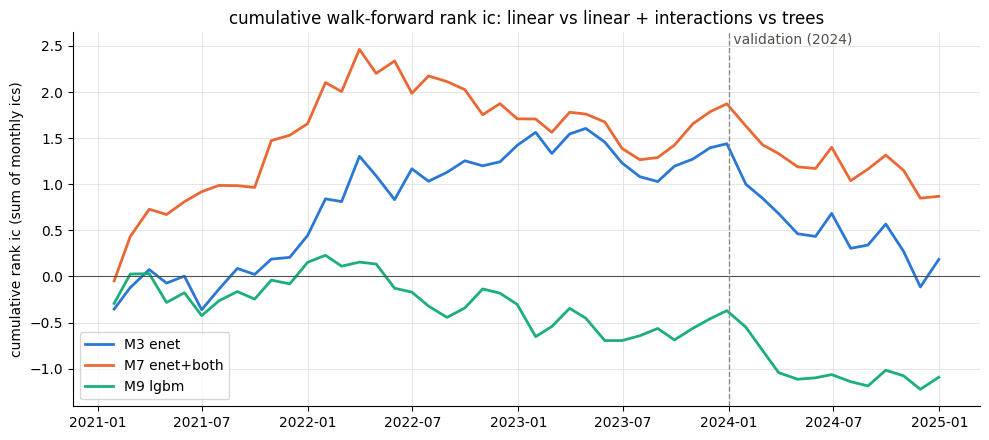

In [23]:
# chart 2: cumulative ic over the 48 months for M3, M7 and M9
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in [("M3", BLUE), ("M7", ORANGE), ("M9", AQUA)]:
    ax.plot(ic_by_model[name].index, ic_by_model[name].cumsum(), color=color, linewidth=2,
            label=name + " " + model_registry[name]["short"])

validation_start = pd.Timestamp("2024-01-01")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.axvline(validation_start, color=GREY, linestyle="--", linewidth=1)
ax.text(validation_start, ax.get_ylim()[1], " validation (2024)", va="top", color="#52514e")
ax.set_ylabel("cumulative rank ic (sum of monthly ics)")
ax.set_title("cumulative walk-forward rank ic: linear vs linear + interactions vs trees")
ax.legend(loc="lower left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "06_cumulative_ic_m3_m7_m9.png", dpi=150)
plt.show()

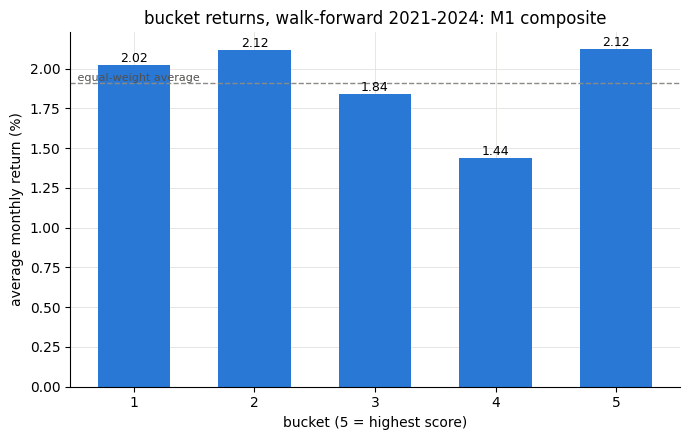

In [24]:
# chart 3: average return of buckets 1-5 for the selected model (walk-forward, 48 months)
bucket_by_date, bucket_means = bucket_returns(scored[chosen_model], "score")
ew_average = benchmark_ew.loc[scored[chosen_model]["Date"].unique()].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(bucket_means.index, bucket_means.values * 100, color=BLUE, width=0.6)
ax.axhline(ew_average, color=GREY, linestyle="--", linewidth=1)
ax.text(0.5, ew_average, " equal-weight average", va="bottom", ha="left", color="#52514e", fontsize=8)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), round(bar.get_height(), 2),
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("bucket (5 = highest score)")
ax.set_ylabel("average monthly return (%)")
ax.set_title("bucket returns, walk-forward 2021-2024: " + chosen_model + " " + model_registry[chosen_model]["short"])
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "07_bucket_returns_selected_model.png", dpi=150)
plt.show()

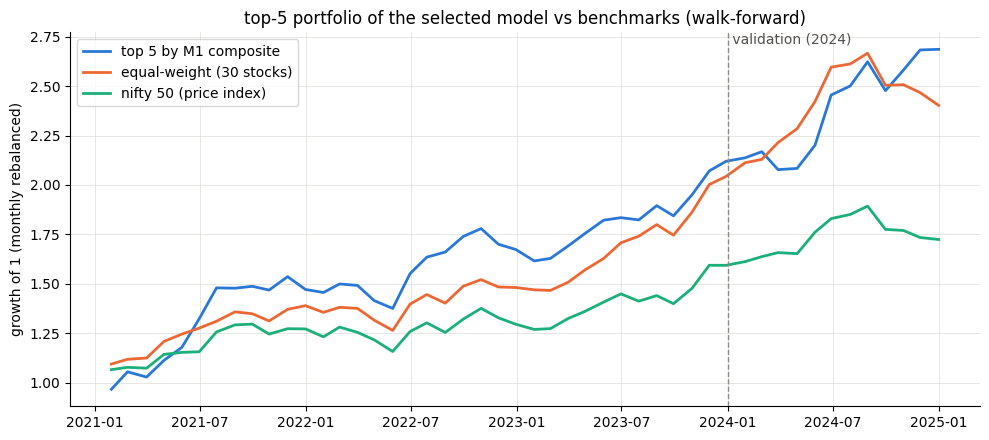

growth of 1 -> top 5: 2.686 | equal-weight: 2.403


In [25]:
# chart 4: top-5 portfolio of the selected model vs equal-weight and nifty (walk-forward 2021-2024)
top5_returns = top_k_returns(scored[chosen_model], "score", 5)
curve_dates = top5_returns.index

try:
    nifty_table = pd.read_csv(BENCHMARK_NIFTY_PATH, parse_dates=["Date"])
    benchmark_nifty = nifty_table.set_index("Date")["fwd_1m"]
except Exception:
    benchmark_nifty = None
    print("WARNING: no nifty file, chart uses equal-weight only")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve_dates, (1 + top5_returns).cumprod(), color=BLUE, linewidth=2,
        label="top 5 by " + chosen_model + " " + model_registry[chosen_model]["short"])
ax.plot(curve_dates, (1 + benchmark_ew.loc[curve_dates]).cumprod(), color=ORANGE, linewidth=2,
        label="equal-weight (30 stocks)")
if benchmark_nifty is not None:
    ax.plot(curve_dates, (1 + benchmark_nifty.loc[curve_dates]).cumprod(), color=AQUA, linewidth=2,
            label="nifty 50 (price index)")

ax.axvline(validation_start, color=GREY, linestyle="--", linewidth=1)
ax.text(validation_start, ax.get_ylim()[1], " validation (2024)", va="top", color="#52514e")
ax.set_ylabel("growth of 1 (monthly rebalanced)")
ax.set_title("top-5 portfolio of the selected model vs benchmarks (walk-forward)")
ax.legend(loc="upper left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "08_top5_selected_model_vs_benchmarks.png", dpi=150)
plt.show()

print("growth of 1 -> top 5:", round((1 + top5_returns).cumprod().iloc[-1], 3),
      "| equal-weight:", round((1 + benchmark_ew.loc[curve_dates]).cumprod().iloc[-1], 3))

## Summary

In [26]:
print("MODEL COMPARISON (walk-forward = 48 months, validation = 2024 only)")
summary_table = comparison[["label", "wf_mean_ic", "wf_ic_ci_low", "wf_ic_ci_high", "wf_icir", "wf_top5_excess_ew",
                            "val_mean_ic", "val_icir", "val_top5_excess_ew"]]
print(summary_table.round(4).to_string())
print()

print("DECOMPOSITION (change in walk-forward mean ic vs the linear model M3)")
print(decomposition.round(4).to_string(index=False))
print()

print("SELECTION REASONING")
for line in selection_lines:
    print(line)
print()

print("CHECK RESULTS")
for name in check_results:
    if check_results[name]:
        print("PASS:", name)
    else:
        print("FAIL:", name)
print("all checks passed:", all(check_results.values()))

MODEL COMPARISON (walk-forward = 48 months, validation = 2024 only)
                                                    label  wf_mean_ic  wf_ic_ci_low  wf_ic_ci_high  wf_icir  wf_top5_excess_ew  val_mean_ic  val_icir  val_top5_excess_ew
model                                                                                                                                                                    
M0     best single feature (mom_1m_n, sign from train ic)      0.0374       -0.0162         0.0956   0.1519             0.0043      -0.1184   -0.4435             -0.0192
M1      equal-weight composite of 7 features with a prior      0.0169       -0.0483         0.0812   0.0620             0.0028      -0.0205   -0.0809              0.0066
M2                                     ols on 17 features     -0.0341       -0.0790         0.0088  -0.1773            -0.0031      -0.0900   -0.4050             -0.0157
M3                             elastic net on 17 features      0.0038       -0.048